# 1. SNR and Mode Content

In [1]:
import numpy as np
import scipy as sp
from scipy.special import jv
import pandas as pd
from collections import defaultdict
import os

from few.trajectory.inspiral import EMRIInspiral
from few.trajectory.ode import KerrEccEqFlux
from few.amplitude.ampinterp2d import AmpInterpKerrEccEq
from few.utils.ylm import GetYlms
from few.utils.geodesic import get_fundamental_frequencies
from few.utils.constants import YRSID_SI, MTSUN_SI

import sys
sys.path.append("../emri_tools")
from utils import PSD
from inspiral import compute_trajectory, mode_energy_inspiral, mode_snr2_inspiral, find_total_snr, find_relevant_modes

import matplotlib
import matplotlib.pyplot as plt
from seaborn import color_palette
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": "Computer Modern",
    "text.latex.preamble": r"\usepackage{amsfonts}",
    "font.size": 17,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "legend.frameon": False
})

In [2]:
traj_gen = EMRIInspiral(func=KerrEccEqFlux)
amp_gen = AmpInterpKerrEccEq()
ylm_gen = GetYlms()

tdi_flag = False
psd = PSD(tdi_flag)

Using LISA PSD


### Configuration

In [3]:
# Fiducial system's parameters
m1, m2 = 1e6, 10.0
a, Tpl = 0.9, 0.9
xI, dist = 1.0, 1.0
theta_S, phi_S = np.pi/3, 0
theta_K, phi_K = np.pi/3, 0

### 1.1. Structure of the SNR Across the Parameter Space

In [4]:
filename = "../results/1_snr_dependencies.csv"

if os.path.exists(filename):
    df = pd.read_csv(filename)
else:
    df = pd.DataFrame(columns=["ef", "m1", "a", "snr"])

vals_ef = [] #np.linspace(0, 0.6, 15)
vals_m1 = [] #10**np.linspace(5, 7, 15)
vals_a = [] #np.array([0, 0.5, 0.9])
vals_snr_total = np.zeros((len(vals_ef), len(vals_m1), len(vals_a)))

for k, a in enumerate(vals_a):
    for j, m1 in enumerate(vals_m1):
        for i, ef in enumerate(vals_ef):

            mask = ((df["ef"] == ef) & (df["m1"] == m1) & (df["a"] == a))

            if mask.any():
                continue
                
            snr = find_total_snr(m1, m2, a, Tpl, ef, xI, dist, theta_K, phi_K, psd, traj_gen, amp_gen, ylm_gen)

            new_row = pd.DataFrame([{
                "ef": ef,
                "m1": m1,
                "a": a,
                "snr": snr
            }])

            df = pd.concat([df, new_row], ignore_index=True)
            df.to_csv(filename, index=False)

/var/folders/gj/qcbvhgm1783bm97qs22klhj00000gn/T/ipykernel_37037/2099556217.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


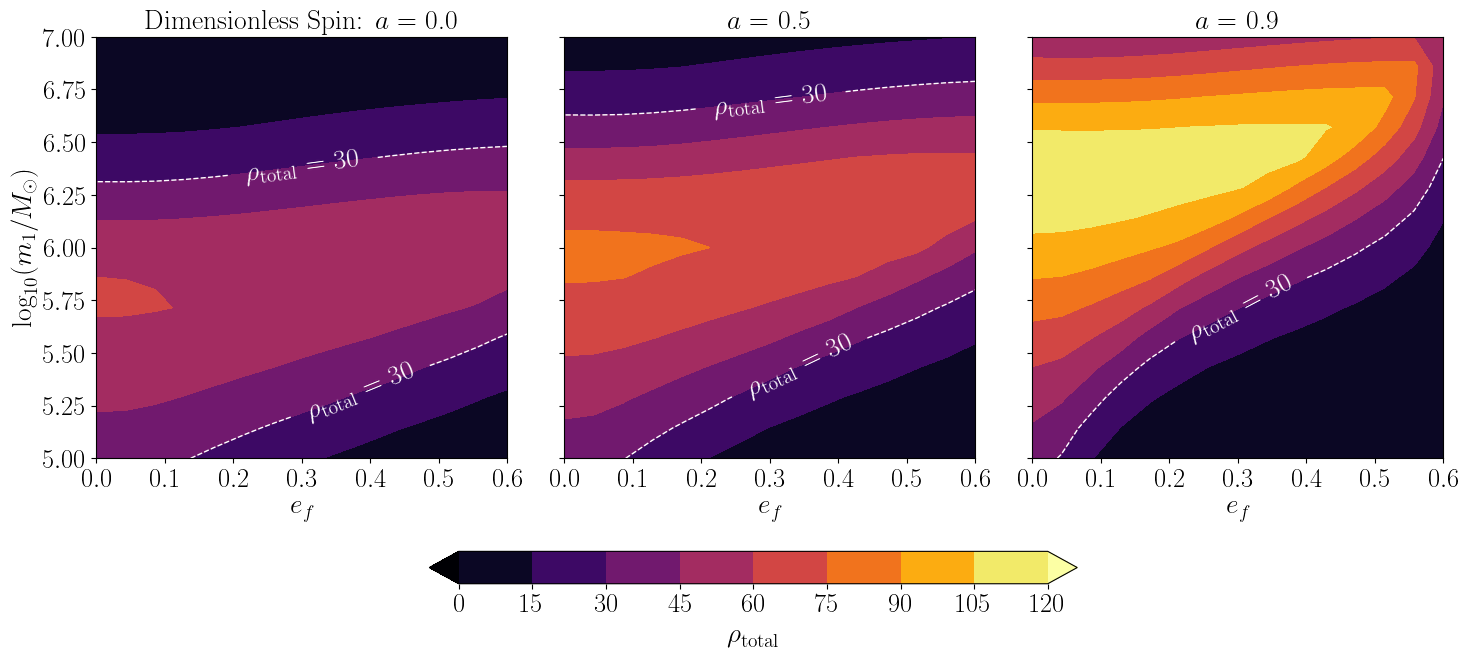

In [5]:
filename = "../results/1_snr_dependencies.csv"
df = pd.read_csv(filename)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

vals_a = np.array([0, 0.5, 0.9])

vmin = 0
vmax = 120

N_levels = 9
levels = np.linspace(vmin, vmax, N_levels)
cmap = plt.cm.inferno

for k, a in enumerate(vals_a):
    
    ax = axes[k]

    sub = df[df["a"] == a]
    pivot = sub.pivot(index="ef", columns="m1", values="snr")

    X = pivot.index.values
    Y = np.log10(pivot.columns.values)
    Z = pivot.values.T

    im = ax.contourf(X, Y, Z, levels=levels, cmap=cmap, extend="both")

    cs = ax.contour(X, Y, Z, levels=[30], colors='white', linestyles='--', linewidths=1)
    ax.clabel(cs, fmt={30: r"$\rho_{\rm total}=30$"}, colors="white", fontsize=20)

    ax.set_xticks(np.arange(0, 0.61, 0.1))
    ax.set_yticks(np.arange(5.00, 7.01, 0.25))
    
    if k == 0:
        ax.set_title(f"Dimensionless Spin: $a$ = {a}", fontsize=20)
    if k != 0:
        ax.set_title(f"$a$ = {a}", fontsize=20)
        
    ax.set_xlabel(r"$e_f$", fontsize=20)

    if k == 0:
        ax.set_ylabel(r"$\log_{10}(m_1 / M_\odot)$", fontsize=20)

    ax.tick_params(axis='both', which='major', labelsize=19)

fig.subplots_adjust(bottom=-0.2)
cbar = fig.colorbar(im, ax=axes, orientation='horizontal', fraction=0.06, pad=0.5)
cbar.ax.tick_params(labelsize=19)
cbar.set_label(r"$\rm \rho_{total}$", fontsize=20)

plt.tight_layout()
#plt.savefig('../figures/1_snr_dependencies.png', dpi=600, bbox_inches='tight')
plt.show()

### 1.2. SNR Distribution Among the Modes

In [6]:
N_e_f = 50
e_f_values = np.linspace(0.0, 0.6, N_e_f)
rel_mode_snr_values = []

for i, e_f in enumerate(e_f_values):
    
    mn_list, mode_snr2 = mode_snr2_inspiral(m1, m2, a, Tpl, e_f, xI, dist, theta_K, phi_K, psd, traj_gen, amp_gen, ylm_gen)
    rel_mode_snr_values.append(np.sqrt(mode_snr2) / np.sqrt(np.sum(mode_snr2)))

rel_mode_snr_values = np.asarray(rel_mode_snr_values)

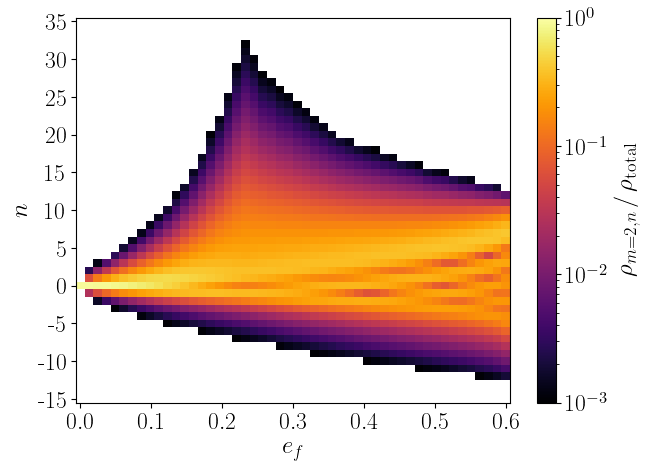

In [7]:
threshold_color = 1e-3
rel_mode_snr_values_plot = rel_mode_snr_values.copy()
rel_mode_snr_values_plot[rel_mode_snr_values_plot < threshold_color] = np.nan

cmap = plt.cm.inferno
cmap.set_bad(color='white')

mask = (mn_list[:,0] == 2) & (mn_list[:,1] >= -15) & (mn_list[:,1] <= 35)
mn_selected = mn_list[mask]
m_values = mn_selected[:, 0]
n_values = mn_selected[:, 1]

Z = rel_mode_snr_values_plot[:, mask]

plt.figure(figsize=(7,5))
plt.pcolormesh(e_f_values, np.arange(len(m_values)), Z.T,
               cmap=cmap,
               norm=matplotlib.colors.LogNorm(vmin=threshold_color, vmax=1))

step = 5
indices = np.arange(0, len(n_values), step)
plt.yticks(indices, n_values[indices], ha='right')
plt.xticks(np.arange(0, 0.61, 0.1))
plt.ylabel(r'$n$')
plt.xlabel(r"$e_f$")
plt.colorbar(label=r"$\rho_{m=2 , n} \, / \, \rho_{\rm total}$")
#plt.savefig('../figures/1_mode_snr_vs_ecc.png', bbox_inches='tight', dpi=600)
plt.show()

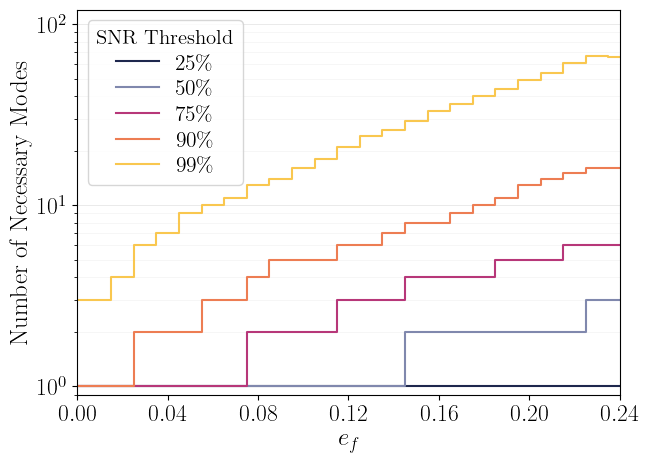

In [8]:
vals_ef = np.arange(0, 0.241, 0.01)

vals_thr = [0.25, 0.5, 0.75, 0.9, 0.99]
cpal = ["#1e274d",
        "#8088ad",
        "#b73779",
        "#ed7d53",
        "#f9c74f"]

plt.figure(figsize=(7,5))

for i, thr in enumerate(vals_thr):

    N_selected_modes = []
    
    for ef in vals_ef:
        
        selected_modes, _, _, _ = find_relevant_modes(m1, m2, a, Tpl, ef, xI, dist, theta_K, phi_K, psd, thr, traj_gen, amp_gen, ylm_gen)
        N_selected_modes.append(len(selected_modes))

    plt.step(vals_ef, N_selected_modes, "-", where="mid", c=cpal[i], label=rf"${thr*100: g}\%$")

plt.xticks(np.arange(0, 0.241, 0.04))
plt.xlim(vals_ef[0], vals_ef[-1]) 
plt.ylim(9e-1, 1.2e2) 
plt.yscale("log")

plt.grid(True, axis='y', which='major', alpha=0.3, linewidth=0.6)
plt.grid(True, axis='y', which='minor', alpha=0.2, linewidth=0.4)

plt.xlabel(r"$e_f$")
plt.ylabel(f"Number of Necessary Modes")
plt.legend(title="SNR Threshold", frameon=True, fontsize=15.5, title_fontsize=15, labelspacing=0.3)
#plt.savefig('../figures/1_number_modes_vs_ecc.pdf', bbox_inches='tight')
plt.show()

### 1.3. Extra: Waveform Frequency Dependence on Eccentricity

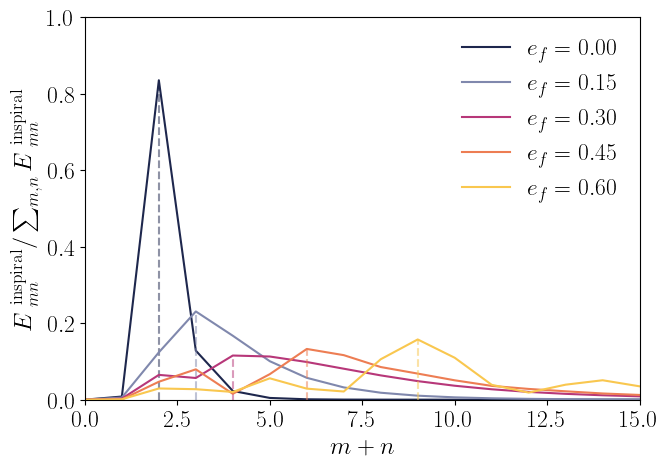

In [9]:
e_f_values = np.arange(0, 0.61, 0.15)
m_plus_n_peak = []

cpal = ["#1e274d",
        "#8088ad",
        "#b73779",
        "#ed7d53",
        "#f9c74f"]

plt.figure(figsize=(7,5))

for ii, e_f in enumerate(e_f_values):

    mn_list, rel_mode_energy = mode_energy_inspiral(
        m1, m2, a, Tpl, e_f, xI, theta_K, phi_K,
        traj_gen, amp_gen, ylm_gen
    )
    
    rel_E_to_sum = defaultdict(list)

    for i, (m, n) in enumerate(mn_list):
        if n < 0:
            continue
        rel_E_to_sum[m+n].append(rel_mode_energy[i])
    
    m_plus_n = sorted(rel_E_to_sum.keys())
    rel_E_m_plus_n = [np.sum(rel_E_to_sum[k]) for k in m_plus_n]
    
    ind_max = np.argmax(rel_E_m_plus_n)
    mpn_peak = m_plus_n[ind_max]
    m_plus_n_peak.append(mpn_peak)
    
    plt.plot(m_plus_n, rel_E_m_plus_n, "-", c=cpal[ii], label=fr"$e_f={e_f:.2f}$")
    plt.vlines(mpn_peak, 0, np.max(rel_E_m_plus_n), cpal[ii], "--", alpha=0.5)

plt.xlabel(r"$m+n$")
plt.ylabel(r"$E_{~mn}^{\rm~inspiral} / \sum_{m,n} E_{~m n}^{\rm~inspiral}$")
plt.xlim([0, 15])
plt.ylim([0, 1])
plt.legend()
plt.tight_layout()
#plt.savefig('../figures/1_mpn_peak.pdf', bbox_inches='tight')
plt.show()

In [10]:
N_ecc = 50
e_f_values = np.linspace(0, 0.6, N_ecc)
m_plus_n_peak = []

for ii, e_f in enumerate(e_f_values):
    
    mn_list, rel_mode_energy = mode_energy_inspiral(
        m1, m2, a, Tpl, e_f, xI, theta_K, phi_K,
        traj_gen, amp_gen, ylm_gen
    )
    
    rel_E_to_sum = defaultdict(list)

    for i, (m, n) in enumerate(mn_list):
        if n < 0:
            continue
        rel_E_to_sum[m+n].append(rel_mode_energy[i])
    
    m_plus_n = sorted(rel_E_to_sum.keys())
    rel_E_m_plus_n = [np.sum(rel_E_to_sum[k]) for k in m_plus_n]
    
    ind_max = np.argmax(rel_E_m_plus_n)
    mpn_peak = m_plus_n[ind_max]
    m_plus_n_peak.append(mpn_peak)

[10.53518728 -0.63407818  1.44696381]


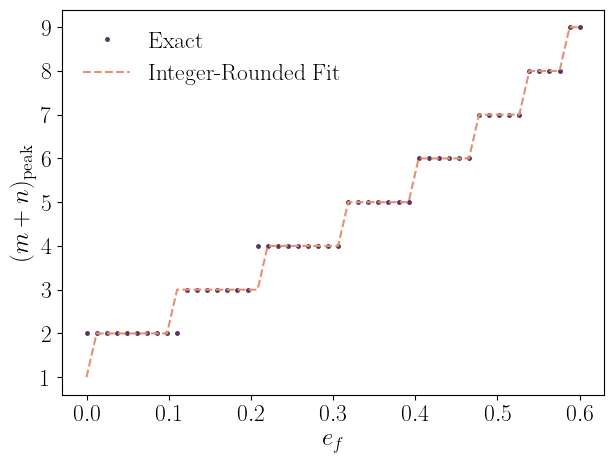

In [11]:
xx = e_f_values
yy = m_plus_n_peak

uniq = np.unique(yy)
xx_means = np.array([xx[yy==k].mean() for k in uniq])
yy_vals = uniq.astype(float)

def model(e, a, b, c):
    return a * (e + b*e**2) * (1 - e**2)**(-3/2) + c

p0 = [1.0, 0.0, 0.0]

popt, pcov = sp.optimize.curve_fit(model, xx_means, yy_vals, p0=p0, maxfev=10000)
print(popt)

model_grid = model(xx, *popt)
model_floor_grid = np.round(model_grid)

plt.figure(figsize=(7,5))

plt.plot(e_f_values, m_plus_n_peak, ".", label="Exact", c="#56365C", markersize=5)
plt.plot(e_f_values, model_floor_grid, "--", label="Integer-Rounded Fit", c="#e68f72", markersize=7)

plt.yticks(np.arange(1, 9.1, 1))
plt.xlabel(r"$e_f$")
plt.ylabel(r"$(m+n)_\mathrm{peak}$")
plt.legend()
#plt.savefig('../figures/1_mpn_peak_vs_ecc.pdf', bbox_inches='tight')
plt.show()

In [12]:
def find_mpn_peak(e_f):
    a, b, c = popt
    return np.round(a * (e_f + b*e_f**2) * (1 - e_f**2)**(-3/2) + c)

e_f_values = np.linspace(0, 0.6, 100)
f_GW_peak_values_few = []

for e_f in e_f_values:

    data = compute_trajectory(m1, m2, a, Tpl, e_f, xI, traj_gen)
    p, e, x = data["p"], data["e"], data["xI"], 
    
    # Get dimensionless fundamental frequencies
    OmegaPhi, OmegaTheta, OmegaR = get_fundamental_frequencies(a, p, e, x)

    mpn_peak = find_mpn_peak(e_f)
    f_Phi_ref = OmegaPhi[-1] / (2 * np.pi * (m1 + m2) * MTSUN_SI) # To get frequency in Hz
    f_GW_peak = mpn_peak * f_Phi_ref
    f_GW_peak_values_few += [f_GW_peak]

In [13]:
def g(n, e):
    
    return (n**4 / 32) * ((jv(n-2, n*e) - 2*e*jv(n-1, n*e) + (2/n)*jv(n, n*e) 
            + 2*e*jv(n+1, n*e) - jv(n+2, n*e))**2 + (1-e**2) * (jv(n-1, n*e)
            - 2*jv(n, n*e) + jv(n+2, n*e))**2 + (4/(3*n**2))*jv(n, n*e)**2)

def mode_energy_inspiral_bessel(vals_n, m1, m2, a, Tpl, e_f, xI, theta_K, phi_K, traj_gen, amp_gen, ylm_gen):
    
    out = compute_trajectory(m1, m2, a, Tpl, e_f, xI, traj_gen)
    t, p, e = out["t"], out["p"], out["e"]
    dt = np.diff(t, append=t[-1])

    vals_mode_energy = np.zeros_like(vals_n, dtype="float64")
    for i, n in enumerate(vals_n):
        vals_g = g(n, e)
        vals_a = p / (1-e**2)
        vals_E_n = (vals_g / vals_a**5) * dt
        vals_mode_energy[i] = np.sum(vals_E_n)

    sum_mode_energy = np.sum(vals_mode_energy)
    vals_mode_energy_rel = vals_mode_energy / sum_mode_energy
    
    return vals_mode_energy_rel

N_ecc = 50
e_f_values = np.linspace(0, 0.6, N_ecc)
vals_n_peak = []

vals_n = np.arange(1, 100, 1)

for ii, e_f in enumerate(e_f_values):
    
    rel_E_n = mode_energy_inspiral_bessel(vals_n, m1, m2, a, Tpl, e_f, xI, theta_K, phi_K, traj_gen, amp_gen, ylm_gen)
    ind_max = np.argmax(rel_E_n)
    n_peak = vals_n[ind_max]
    vals_n_peak.append(n_peak)

xx = e_f_values
yy = vals_n_peak

uniq = np.unique(yy)
xx_means = np.array([xx[yy==k].mean() for k in uniq])
yy_vals = uniq.astype(float)

def model(e, c1, c2, c3, c4):
    return 2 * (1 + c1 * e + c2 * e**2 + c3 * e**3 + c4 * e**4) * (1 - e**2)**(-3/2)

p0 = [0, 0, 0, 0]

popt, pcov = sp.optimize.curve_fit(model, xx_means, yy_vals, p0=p0, maxfev=10000)
print(popt)

model_grid = model(xx, *popt)
model_floor_grid = np.round(model_grid)

def find_n_peak(e_f):
    c1, c2, c3, c4 = popt
    return np.round(2 * (1 + c1 * e_f + c2 * e_f**2 + c3 * e_f**3 + c4 * e_f**4) * (1 - e_f**2)**(-3/2))

e_f_values = np.linspace(0, 0.6, 100)
f_GW_peak_values_bessel = []

for e_f in e_f_values:

    data = compute_trajectory(m1, m2, a, Tpl, e_f, xI, traj_gen)
    p, e, x = data["p"], data["e"], data["xI"], 
    
    # Get dimensionless fundamental frequencies
    OmegaPhi, OmegaTheta, OmegaR = get_fundamental_frequencies(a, p, e, x)

    n_peak = find_n_peak(e_f)
    f_Phi_ref = OmegaPhi[-1] / (2 * np.pi * (m1 + m2) * MTSUN_SI) # To get frequency in Hz
    f_GW_peak = n_peak * f_Phi_ref
    f_GW_peak_values_bessel += [f_GW_peak]

[ -1.2957718   11.89236332 -13.58028104   0.53652543]


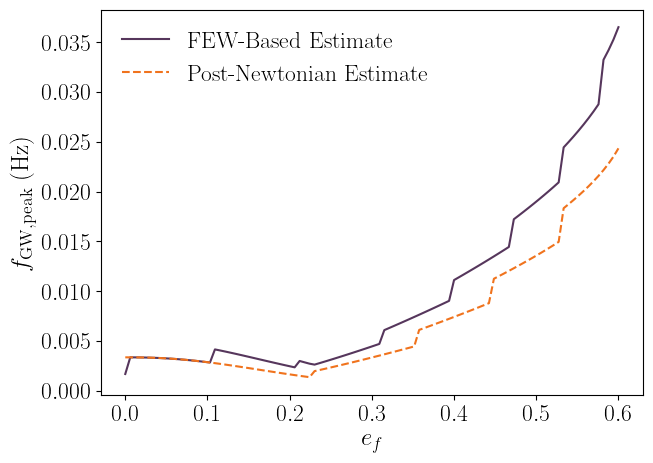

In [14]:
plt.figure(figsize=(7,5))

plt.plot(e_f_values, f_GW_peak_values_few, "-", label="FEW-Based Estimate", c="#56365C")
plt.plot(e_f_values, f_GW_peak_values_bessel, "--", label="Post-Newtonian Estimate", c="#f0731d")

plt.xlabel(r"$e_f$")
plt.ylabel(r"$f_\mathrm{GW, peak} ~ (\textrm{Hz})$")
plt.legend()
#plt.savefig('../figures/1_freq_peak_vs_ecc_comparison.pdf', bbox_inches='tight')
plt.show()

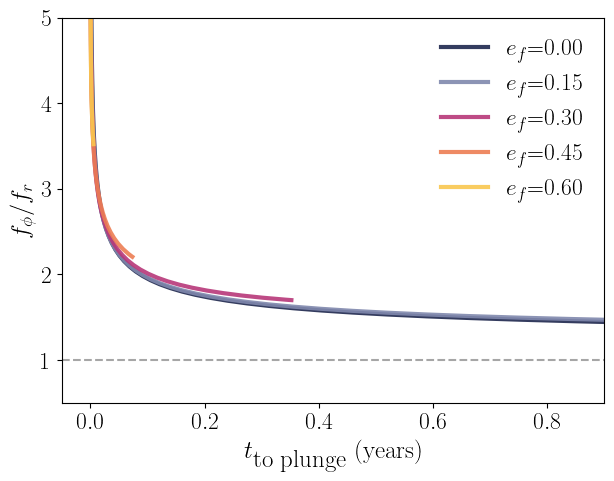

In [15]:
vals_ef = np.arange(0, 0.61, 0.15)

plt.figure(figsize=(7,5))

for ef, color in zip(vals_ef, cpal):
    
    data = compute_trajectory(m1, m2, a, 0.9, ef, xI, traj_gen)
    t, p, e, x = data["t"], data["p"], data["e"], data["xI"], 
    OmegaPhi, OmegaTheta, OmegaR = get_fundamental_frequencies(a, p, e, x)
    plt.plot(t/YRSID_SI, OmegaPhi/OmegaR, label=rf"$e_f$={ef:.2f}", c=color, lw=3, alpha=0.9)

plt.axhline(1, linestyle="--", color="gray", alpha=0.7)

plt.xlim([-0.05, 0.9])
plt.xlabel(r"$t_\textrm{to plunge}$ (years)")
plt.ylabel(r"$f_\phi / f_r$")
plt.ylim([0.5,5])
plt.legend()
#plt.savefig('../figures/1_freqs_ratio.pdf', bbox_inches='tight')
plt.show()